In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv("ecommerce_customer_behavior_dataset-selected-columns.csv")

In [12]:
df.head(5)

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount
0,ORD_001337,CUST_01337,2023-01-01,27,Female,Bursa,Toys,54.28,1,0.00
1,ORD_004885,CUST_04885,2023-01-01,42,Male,Konya,Toys,244.90,1,0.00
2,ORD_004507,CUST_04507,2023-01-01,43,Female,Ankara,Food,48.15,5,0.00
3,ORD_000645,CUST_00645,2023-01-01,32,Male,Istanbul,Electronics,804.06,1,229.28
4,ORD_000690,CUST_00690,2023-01-01,40,Female,Istanbul,Sports,755.61,5,0.00


In [11]:
print(df.shape)

(5000, 10)


In [13]:
print(df.columns)

Index(['Order_ID', 'Customer_ID', 'Date', 'Age', 'Gender', 'City',
       'Product_Category', 'Unit_Price', 'Quantity', 'Discount_Amount'],
      dtype='object')


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          5000 non-null   object 
 1   Customer_ID       5000 non-null   object 
 2   Date              5000 non-null   object 
 3   Age               5000 non-null   int64  
 4   Gender            5000 non-null   object 
 5   City              5000 non-null   object 
 6   Product_Category  5000 non-null   object 
 7   Unit_Price        5000 non-null   float64
 8   Quantity          5000 non-null   int64  
 9   Discount_Amount   5000 non-null   float64
dtypes: float64(2), int64(2), object(6)
memory usage: 390.8+ KB


In [16]:
df.describe()

,Age,Unit_Price,Quantity,Discount_Amount
count,5000.000000,5000.000000,5000.000000,5000.000000
mean,35.032600,455.834120,2.220000,24.852804
std,11.080546,712.477209,1.398711,88.385124
min,18.000000,5.180000,1.000000,0.000000
25%,27.000000,76.587500,1.000000,0.000000
50%,35.000000,182.950000,2.000000,0.000000
75%,42.000000,513.930000,3.000000,8.760000
max,75.000000,7159.450000,5.000000,1525.550000


In [18]:
df.isnull().sum()

,0
Order_ID,0
Customer_ID,0
Date,0
Age,0
Gender,0
City,0
Product_Category,0
Unit_Price,0
Quantity,0
Discount_Amount,0


In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
df.dtypes

,0
Order_ID,object
Customer_ID,object
Date,object
Age,int64
Gender,object
City,object
Product_Category,object
Unit_Price,float64
Quantity,int64
Discount_Amount,float64


In [21]:
print("Toplam satır:", df.shape[0])
print("Toplam sütun:", df.shape[1])
print("Eksik değer:", df.isnull().sum().sum())
print("Tekrarlanan kayıt:", df.duplicated().sum())

Toplam satır: 5000
Toplam sütun: 10
Eksik değer: 0
Tekrarlanan kayıt: 0


In [22]:
df.select_dtypes(include="object").nunique()

,0
Order_ID,5000
Customer_ID,5000
Date,451
Gender,3
City,10
Product_Category,8


In [23]:
df.select_dtypes(include="number").describe().T

,count,mean,std,min,25%,50%,75%,max
Age,5000.0,35.032600,11.080546,18.00,27.0000,35.00,42.00,75.00
Unit_Price,5000.0,455.834120,712.477209,5.18,76.5875,182.95,513.93,7159.45
Quantity,5000.0,2.220000,1.398711,1.00,1.0000,2.00,3.00,5.00
Discount_Amount,5000.0,24.852804,88.385124,0.00,0.0000,0.00,8.76,1525.55


In [24]:
df.columns.tolist()

['Order_ID',
 'Customer_ID',
 'Date',
 'Age',
 'Gender',
 'City',
 'Product_Category',
 'Unit_Price',
 'Quantity',
 'Discount_Amount']

In [25]:
df["Date"] = pd.to_datetime(df["Date"])

In [26]:
df["Total_Sales"] = (
    df["Unit_Price"] * df["Quantity"]
    - df["Discount_Amount"]
)

In [27]:
print("Toplam satış:", df["Total_Sales"].sum())

print("Ortalama sipariş tutarı:",
      df["Total_Sales"].mean())

print("En yüksek satış:",
      df["Total_Sales"].max())

print("En düşük satış:",
      df["Total_Sales"].min())

Toplam satış: 4915544.57
Ortalama sipariş tutarı: 983.108914
En yüksek satış: 22023.899999999998
En düşük satış: 7.87


In [28]:
df.head(10)

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Sales
0,ORD_001337,CUST_01337,2023-01-01,27,Female,Bursa,Toys,54.28,1,0.00,54.28
1,ORD_004885,CUST_04885,2023-01-01,42,Male,Konya,Toys,244.90,1,0.00,244.90
2,ORD_004507,CUST_04507,2023-01-01,43,Female,Ankara,Food,48.15,5,0.00,240.75
3,ORD_000645,CUST_00645,2023-01-01,32,Male,Istanbul,Electronics,804.06,1,229.28,574.78
4,ORD_000690,CUST_00690,2023-01-01,40,Female,Istanbul,Sports,755.61,5,0.00,3778.05
5,ORD_000223,CUST_00223,2023-01-01,43,Female,Istanbul,Beauty,122.46,1,0.00,122.46
6,ORD_002506,CUST_02506,2023-01-01,25,Female,Izmir,Electronics,2107.37,2,0.00,4214.74
7,ORD_004540,CUST_04540,2023-01-01,44,Male,Konya,Food,213.64,2,0.00,427.28
8,ORD_001808,CUST_01808,2023-01-02,41,Male,Istanbul,Fashion,257.62,5,62.15,1225.95
9,ORD_003413,CUST_03413,2023-01-02,58,Male,Istanbul,Sports,1784.75,4,490.25,6648.75


In [29]:
category_sales = df.groupby("Product_Category")["Total_Sales"].sum().sort_values(ascending=False)

print(category_sales)

Product_Category
Electronics      2328806.81
Home & Garden     908348.86
Sports            754563.56
Fashion           375214.93
Toys              223142.48
Beauty            156584.74
Food               96138.67
Books              72744.52
Name: Total_Sales, dtype: float64


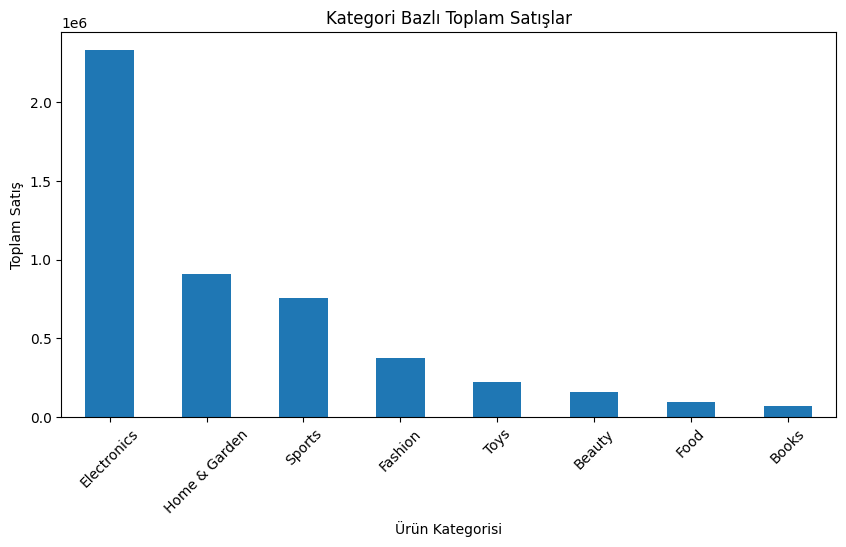

In [30]:
category_sales.plot(
    kind="bar",
    figsize=(10,5),
    title="Kategori Bazlı Toplam Satışlar"
)

plt.xlabel("Ürün Kategorisi")
plt.ylabel("Toplam Satış")
plt.xticks(rotation=45)
plt.show()

In [31]:
city_sales = df.groupby("City")["Total_Sales"].sum().sort_values(ascending=False)

print(city_sales)

City
Istanbul     1334122.56
Ankara        657535.82
Izmir         567534.67
Bursa         459076.31
Adana         427059.63
Konya         344974.94
Gaziantep     318408.41
Antalya       315549.89
Kayseri       312303.91
Eskisehir     178978.43
Name: Total_Sales, dtype: float64


In [32]:
customer_sales = df.groupby("Customer_ID")["Total_Sales"].sum().sort_values(ascending=False)

print(customer_sales.head(10))

Customer_ID
CUST_04705    22023.90
CUST_00061    21478.35
CUST_01984    21409.05
CUST_00525    20211.81
CUST_03721    19547.20
CUST_03174    18728.68
CUST_02052    18699.75
CUST_03494    18014.55
CUST_00472    17099.30
CUST_00642    16214.20
Name: Total_Sales, dtype: float64


In [36]:
order_count = df.groupby("Customer_ID")["Order_ID"].count()

print(order_count.describe())

count    5000.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: Order_ID, dtype: float64


In [37]:
print("Tek sipariş veren müşteri sayısı:", (order_count == 1).sum())
print("Birden fazla sipariş veren:", (order_count > 1).sum())

Tek sipariş veren müşteri sayısı: 5000
Birden fazla sipariş veren: 0


In [33]:
gender_sales = df.groupby("Gender")["Total_Sales"].sum()

print(gender_sales)

Gender
Female    2474009.26
Male      2381028.70
Other       60506.61
Name: Total_Sales, dtype: float64


In [34]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 18, 25, 35, 45, 55, 100],
    labels=["18 altı", "18-25", "26-35", "36-45", "46-55", "55 üzeri"]
)

age_sales = df.groupby("Age_Group", observed=False)["Total_Sales"].sum()

print(age_sales)

Age_Group
18 altı      469510.36
18-25        674920.04
26-35       1436643.56
36-45       1480389.66
46-55        673097.85
55 üzeri     180983.10
Name: Total_Sales, dtype: float64


In [38]:
df["Ay"] = df["Date"].dt.to_period("M")

aylik = df.groupby("Ay")["Total_Sales"].sum()

print(aylik)

Ay
2023-01    286694.32
2023-02    338784.92
2023-03    321716.01
2023-04    257332.58
2023-05    351902.03
2023-06    324356.96
2023-07    346618.03
2023-08    391505.89
2023-09    262602.86
2023-10    352286.61
2023-11    282606.10
2023-12    384717.52
2024-01    396874.92
2024-02    342913.06
2024-03    274632.76
Freq: M, Name: Total_Sales, dtype: float64


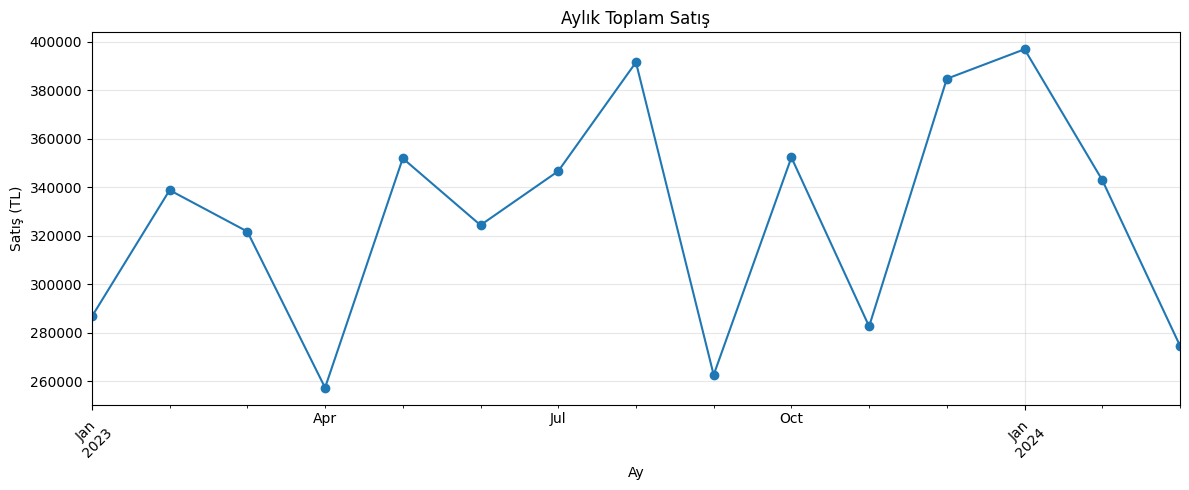

In [39]:
aylik.plot(kind="line", marker="o", figsize=(12,5))
plt.title("Aylık Toplam Satış")
plt.ylabel("Satış (TL)")
plt.xlabel("Ay")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
df["Gun"] = df["Date"].dt.day_name()

gun_satis = df.groupby("Gun")["Total_Sales"].sum()

gun_siralama = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
gun_satis = gun_satis.reindex(gun_siralama)

print(gun_satis)

Gun
Monday       817399.03
Tuesday      768221.72
Wednesday    670605.98
Thursday     663871.24
Friday       669175.46
Saturday     659414.02
Sunday       666857.12
Name: Total_Sales, dtype: float64
